# Machine Learning-Based Road Accident Risk Prediction for Kumasi, Ghana

**Course project:** Supervised Machine Learning (Classification)
**Presentation date:** 10 October 2026, 3:00 PM
**Target variable:** `accident_risk_level` → **Low**, **Medium** or **High**

> ⚠️ **Important note about the data:** every record in this notebook is **synthetic** (computer-generated) and was created for **academic demonstration only**. It is **not** official accident statistics from the Ghana Police Service, the National Road Safety Authority (NRSA), the Motor Traffic and Transport Department (MTTD) or any other agency.

## 1. Introduction

**What is this project?**
This project builds a *supervised machine-learning classification system* that estimates the **risk level of a road situation in Kumasi**. A "situation" is described by conditions such as the area, the time of day, the weather, the road condition, the traffic volume, vehicle speed and pedestrian activity. The model classifies the situation as **Low Risk**, **Medium Risk** or **High Risk**.

**What the project does *not* do:**
It does **not** predict the exact time or exact place an accident will happen. It only estimates *how risky* a set of conditions is, based on patterns learned from the training data.

**The problem being addressed**
Many factors affect road safety at the same time (rain, bad roads, darkness, speeding, crowded pedestrians, tired drivers...). It is difficult for a person to weigh all of these factors together. A machine-learning model can learn how combinations of factors relate to risk.

**Why road accident risk is important**
- Road accidents cause injuries, deaths, property damage and economic loss.
- Understanding *which conditions* are risky helps planners, police and road-safety agencies decide where to place warnings, lighting, patrols or road repairs.
- Pedestrians, drivers, commercial drivers and passengers can all benefit from risk awareness.

**Why Kumasi was selected**
Kumasi is the capital of the Ashanti Region and one of the busiest cities in Ghana. It has very busy commercial zones (Kejetia, Adum, Kumasi Central, Suame), a large student population (KNUST, Ayigya), heavy use of trotros, taxis and motorbikes, many junctions and roundabouts, and a rainy season that can worsen road conditions. These characteristics make it an interesting and relevant place to study road-risk factors.

## 2. Problem Statement

Assessing road accident risk is difficult because risk does not depend on a single factor. Weather, road condition, lighting, visibility, traffic volume, vehicle speed, pedestrian activity and driver fatigue all interact with one another, and their combined effect is hard to judge by eye or by simple rules. In busy areas of Kumasi such as Kejetia, Adum and Suame, many of these factors are present at the same time. This project applies supervised machine learning to learn the relationship between these conditions and a risk label, so that a new road situation can be quickly classified as **Low, Medium or High risk** to support awareness and decision-making.

## 3. Objectives

**General objective**
To develop and evaluate a machine-learning classification system that estimates the road accident *risk level* (Low, Medium, High) for different road situations in Kumasi.

**Specific objectives**
1. To create a reproducible synthetic dataset of at least 2,000 Kumasi road situations with realistic relationships between conditions and risk.
2. To explore the data visually and identify which conditions are linked to higher risk.
3. To preprocess the data correctly (one-hot encoding and scaling) using a pipeline that avoids data leakage.
4. To train three classifiers: Logistic Regression, Decision Tree and Random Forest.
5. To evaluate the models using accuracy, precision, recall, F1-score, classification reports and a confusion matrix.
6. To select the best model using the evaluation results, and use it to classify a new hypothetical Kumasi situation.
7. To interpret which factors influence the model and to discuss the limitations and future improvements of the project.

## 4. Dataset Creation

### 4.1 Import the libraries
We import the Python libraries used in the whole notebook:
- `numpy` and `pandas` for numbers and tables,
- `matplotlib` and `seaborn` for graphs,
- `scikit-learn` (`sklearn`) for preprocessing, models and evaluation.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

warnings.filterwarnings("ignore")      # keep the notebook output clean
sns.set_theme(style="whitegrid")       # a clean, readable plot style
RANDOM_STATE = 42                      # one seed used everywhere → reproducible results

### 4.2 How the synthetic data is created

Because official, detailed accident records were not available for this academic project, I generate a **synthetic dataset** in Python. The steps are:

1. **Choose the area, day and time** of each record (16 Kumasi locations).
2. **Generate the road conditions** (traffic, pedestrians, weather, lighting, road quality, etc.). Each area has a simple "profile" so that, for example, Kejetia and Kumasi Central tend to have heavier traffic and pedestrian activity than Ahodwo, and KNUST/Ayigya tend to have many pedestrians. These profiles are **assumptions made for the simulation**, not measured facts.
3. **Calculate a hidden "risk score"** by adding up points for risky conditions (poor road, rain, darkness, poor visibility, high speed, heavy traffic, heavy pedestrian activity, driver fatigue, etc.), plus a few combinations (for example *rain + poor road*).
4. **Add random noise** to the score. This is important: in real life, two similar situations do not always have the same outcome. The noise stops the dataset from being "too perfect", so the model cannot reach an unrealistic 100% accuracy.
5. **Convert the score into Low / Medium / High** using cut-off points.
6. **Remove the hidden score** from the dataset, so the model only sees the real input features.

> The relationships are **assumptions** based on common road-safety reasoning. The dataset does **not** represent official accident statistics.

In [2]:
# ---------- 1. Basic settings ----------
rng = np.random.default_rng(42)     # random number generator with seed 42 (reproducible)
n_records = 2400                    # number of synthetic records (more than the required 2,000)

areas = ["Adum", "Kejetia", "Suame", "Asokwa", "Bantama", "Ahodwo", "Kwadaso", "Tafo",
         "Ayigya", "Oforikrom", "KNUST", "Atonsu", "Santasi", "Manhyia", "Dichemso",
         "Kumasi Central"]
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
times = ["Early Morning", "Morning Rush", "Midday", "Afternoon", "Evening Rush", "Night"]
# Early Morning 5:00-6:59 | Morning Rush 7:00-9:59 | Midday 10:00-13:59
# Afternoon 14:00-16:59   | Evening Rush 17:00-19:59 | Night 20:00-4:59
time_probs = [0.08, 0.20, 0.20, 0.18, 0.20, 0.14]   # how often each time period appears

# ---------- 2. Area profiles (assumed values from 0 to 1; higher = more of that thing) ----------
# order: traffic, pedestrians, commercial, public transport, poor roads, accident history
area_profiles = {
    "Adum":           dict(traffic=0.85, pedestrian=0.85, commercial=0.90, transport=0.80, poor_road=0.30, history=0.70),
    "Kejetia":        dict(traffic=0.95, pedestrian=0.95, commercial=0.95, transport=0.95, poor_road=0.45, history=0.90),
    "Suame":          dict(traffic=0.85, pedestrian=0.70, commercial=0.85, transport=0.80, poor_road=0.65, history=0.85),
    "Asokwa":         dict(traffic=0.60, pedestrian=0.50, commercial=0.50, transport=0.55, poor_road=0.45, history=0.55),
    "Bantama":        dict(traffic=0.70, pedestrian=0.65, commercial=0.75, transport=0.65, poor_road=0.40, history=0.60),
    "Ahodwo":         dict(traffic=0.55, pedestrian=0.40, commercial=0.50, transport=0.45, poor_road=0.15, history=0.40),
    "Kwadaso":        dict(traffic=0.60, pedestrian=0.55, commercial=0.60, transport=0.60, poor_road=0.45, history=0.50),
    "Tafo":           dict(traffic=0.55, pedestrian=0.55, commercial=0.60, transport=0.60, poor_road=0.50, history=0.50),
    "Ayigya":         dict(traffic=0.50, pedestrian=0.80, commercial=0.55, transport=0.60, poor_road=0.35, history=0.50),
    "Oforikrom":      dict(traffic=0.60, pedestrian=0.60, commercial=0.55, transport=0.65, poor_road=0.40, history=0.55),
    "KNUST":          dict(traffic=0.55, pedestrian=0.90, commercial=0.45, transport=0.65, poor_road=0.15, history=0.45),
    "Atonsu":         dict(traffic=0.55, pedestrian=0.50, commercial=0.60, transport=0.55, poor_road=0.50, history=0.45),
    "Santasi":        dict(traffic=0.65, pedestrian=0.60, commercial=0.70, transport=0.60, poor_road=0.30, history=0.55),
    "Manhyia":        dict(traffic=0.55, pedestrian=0.50, commercial=0.55, transport=0.55, poor_road=0.30, history=0.45),
    "Dichemso":       dict(traffic=0.65, pedestrian=0.70, commercial=0.75, transport=0.70, poor_road=0.40, history=0.60),
    "Kumasi Central": dict(traffic=0.90, pedestrian=0.90, commercial=0.90, transport=0.85, poor_road=0.30, history=0.80),
}

# How the time of day changes traffic and pedestrians (small adjustments)
time_traffic_adj = {"Early Morning": -0.25, "Morning Rush": 0.20, "Midday": 0.00,
                    "Afternoon": 0.05, "Evening Rush": 0.25, "Night": -0.30}
time_pedestrian_adj = {"Early Morning": -0.20, "Morning Rush": 0.10, "Midday": 0.15,
                       "Afternoon": 0.10, "Evening Rush": 0.10, "Night": -0.25}

# Lighting depends on the time of day: probabilities for [Well Lit, Dim, Dark]
lighting_probs = {"Early Morning": [0.35, 0.35, 0.30], "Morning Rush": [0.88, 0.10, 0.02],
                  "Midday": [0.98, 0.02, 0.00], "Afternoon": [0.97, 0.03, 0.00],
                  "Evening Rush": [0.60, 0.30, 0.10], "Night": [0.20, 0.35, 0.45]}

# Visibility depends on the weather: probabilities for [Good, Moderate, Poor]
visibility_probs = {"Clear": [0.80, 0.18, 0.02], "Cloudy": [0.60, 0.30, 0.10],
                    "Rainy": [0.15, 0.45, 0.40], "Harmattan Haze": [0.10, 0.40, 0.50]}

In [3]:
# ---------- 3. A small helper to turn a number (0 to 1) into Low / Medium / High ----------
# A score near 0 gives mostly "Low"; a score near 1 gives mostly "High"; the middle gives mostly "Medium".
levels = ["Low", "Medium", "High"]
level_number = {"Low": 0, "Medium": 1, "High": 2}

def pick_level(score):
    score = min(max(score, 0.05), 0.95)                 # keep the score between 0.05 and 0.95
    weights = np.array([1 - score, 0.8, score])         # weights for Low, Medium, High
    return rng.choice(levels, p=weights / weights.sum())

# ---------- 4. Generate one record at a time ----------
records = []
for _ in range(n_records):
    area = rng.choice(areas)
    profile = area_profiles[area]
    day = rng.choice(days)
    time_of_day = rng.choice(times, p=time_probs)

    # Sunday is usually quieter on the roads and in the markets
    sunday = (day == "Sunday")
    saturday = (day == "Saturday")

    # Weather, lighting, visibility
    weather = rng.choice(["Clear", "Cloudy", "Rainy", "Harmattan Haze"], p=[0.38, 0.27, 0.28, 0.07])
    lighting = rng.choice(["Well Lit", "Dim", "Dark"], p=lighting_probs[time_of_day])
    visibility = rng.choice(["Good", "Moderate", "Poor"], p=visibility_probs[weather])
    if lighting == "Dark" and rng.random() < 0.25:       # darkness can make visibility worse
        visibility = {"Good": "Moderate", "Moderate": "Poor", "Poor": "Poor"}[visibility]

    # Road condition: more likely to be poor in some areas, and a bit more likely when it rains
    poor_chance = min(profile["poor_road"] + (0.10 if weather == "Rainy" else 0), 0.90)
    road_condition = rng.choice(["Good", "Fair", "Poor"],
                                p=[(1 - poor_chance) * 0.55, (1 - poor_chance) * 0.45, poor_chance])
    road_type = rng.choice(["Major Road", "Minor Road", "Junction", "Roundabout"], p=[0.35, 0.25, 0.30, 0.10])

    # Traffic, congestion, activity levels
    traffic_volume = pick_level(profile["traffic"] + time_traffic_adj[time_of_day] - (0.20 if sunday else 0)
                                + rng.normal(0, 0.10))
    traffic_congestion = pick_level(0.15 + 0.35 * level_number[traffic_volume] + rng.normal(0, 0.10))
    pedestrian_activity = pick_level(profile["pedestrian"] + time_pedestrian_adj[time_of_day]
                                     + rng.normal(0, 0.10))
    commercial_activity = pick_level(profile["commercial"] + time_pedestrian_adj[time_of_day]
                                     - (0.30 if sunday else 0) + (0.10 if saturday else 0) + rng.normal(0, 0.10))
    public_transport_activity = pick_level(profile["transport"] + time_traffic_adj[time_of_day]
                                           + rng.normal(0, 0.10))

    # Vehicle speed: higher on major roads and at night, lower when congestion is high
    speed_score = (0.45 + 0.15 * (road_type == "Major Road") - 0.15 * level_number[traffic_congestion]
                   + (0.20 if time_of_day in ["Night", "Early Morning"] else 0) + rng.normal(0, 0.10))
    vehicle_speed_level = pick_level(speed_score)

    # Driver fatigue is more likely late at night and very early in the morning
    fatigue_chance = {"Night": 0.25, "Early Morning": 0.20}.get(time_of_day, 0.08)
    driver_fatigue = "Yes" if rng.random() < fatigue_chance else "No"

    # Previous accident frequency depends on the area's assumed history
    previous_accident_frequency = pick_level(profile["history"] + rng.normal(0, 0.15))

    # Number of vehicles and pedestrians (counted per hour) follow the traffic and pedestrian levels
    vehicle_means = {"Low": 150, "Medium": 400, "High": 750}
    pedestrian_means = {"Low": 40, "Medium": 130, "High": 260}
    number_of_vehicles = int(np.clip(rng.normal(vehicle_means[traffic_volume], 90), 20, 1100))
    number_of_pedestrians = int(np.clip(rng.normal(pedestrian_means[pedestrian_activity], 45), 5, 450))

    records.append({
        "area": area, "day_of_week": day, "time_of_day": time_of_day,
        "weather_condition": weather, "road_condition": road_condition,
        "lighting_condition": lighting, "traffic_volume": traffic_volume,
        "traffic_congestion": traffic_congestion, "road_type": road_type,
        "vehicle_speed_level": vehicle_speed_level, "pedestrian_activity": pedestrian_activity,
        "commercial_activity": commercial_activity,
        "public_transport_activity": public_transport_activity,
        "driver_fatigue": driver_fatigue, "road_visibility": visibility,
        "number_of_vehicles": number_of_vehicles, "number_of_pedestrians": number_of_pedestrians,
        "previous_accident_frequency": previous_accident_frequency,
    })

synthetic_df = pd.DataFrame(records)
print("Features generated:", synthetic_df.shape)

Features generated: (2400, 18)


### 4.3 Create the target variable `accident_risk_level`

Now I calculate the hidden risk score. Every risky condition adds "risk points". Some **combinations** (for example rain on a poor road) add extra points. Then I add **random noise** (`rng.normal(0, 0.8)`) so that the labels are realistic and not perfectly predictable.

In [4]:
# ---------- Risk points for each condition (assumptions based on common road-safety reasoning) ----------
points_road       = {"Good": 0, "Fair": 0.6, "Poor": 1.5}
points_weather    = {"Clear": 0, "Cloudy": 0.2, "Rainy": 0.9, "Harmattan Haze": 0.6}
points_lighting   = {"Well Lit": 0, "Dim": 0.5, "Dark": 1.0}
points_visibility = {"Good": 0, "Moderate": 0.5, "Poor": 1.2}
points_traffic    = {"Low": 0, "Medium": 0.4, "High": 0.9}
points_congestion = {"Low": 0, "Medium": 0.25, "High": 0.5}
points_road_type  = {"Minor Road": 0, "Roundabout": 0.4, "Major Road": 0.5, "Junction": 0.6}
points_speed      = {"Low": 0, "Medium": 0.5, "High": 1.3}
points_pedestrian = {"Low": 0, "Medium": 0.3, "High": 0.8}
points_commercial = {"Low": 0, "Medium": 0.15, "High": 0.4}
points_transport  = {"Low": 0, "Medium": 0.2, "High": 0.5}
points_previous   = {"Low": 0, "Medium": 0.4, "High": 1.0}
points_time       = {"Early Morning": 0.2, "Morning Rush": 0.2, "Midday": 0, "Afternoon": 0.1,
                     "Evening Rush": 0.3, "Night": 0.4}
points_day        = {"Friday": 0.15, "Saturday": 0.15}     # other days get 0

d = synthetic_df   # short name to keep the lines readable

risk_score = (
    d["road_condition"].map(points_road) + d["weather_condition"].map(points_weather)
    + d["lighting_condition"].map(points_lighting) + d["road_visibility"].map(points_visibility)
    + d["traffic_volume"].map(points_traffic) + d["traffic_congestion"].map(points_congestion)
    + d["road_type"].map(points_road_type) + d["vehicle_speed_level"].map(points_speed)
    + d["pedestrian_activity"].map(points_pedestrian) + d["commercial_activity"].map(points_commercial)
    + d["public_transport_activity"].map(points_transport)
    + d["previous_accident_frequency"].map(points_previous)
    + d["time_of_day"].map(points_time) + d["day_of_week"].map(points_day).fillna(0)
    + (d["driver_fatigue"] == "Yes") * 0.7
    + (d["number_of_vehicles"] / 1000) * 0.8          # more vehicles → a little more risk
    + (d["number_of_pedestrians"] / 500) * 0.5        # more pedestrians → a little more risk
)

# ---------- Combinations that make things worse together ----------
risk_score += ((d["weather_condition"] == "Rainy") & (d["road_condition"] == "Poor")) * 0.6
risk_score += ((d["vehicle_speed_level"] == "High") & (d["road_visibility"] == "Poor")) * 0.6
risk_score += ((d["pedestrian_activity"] == "High") & (d["lighting_condition"] == "Dark")) * 0.5

# ---------- Random noise: real life is never perfectly predictable ----------
risk_score = risk_score + rng.normal(0, 0.8, size=n_records)

# ---------- Convert the score to Low / Medium / High ----------
# Cut-offs: about 40% Low, 35% Medium and 25% High
low_cutoff = np.quantile(risk_score, 0.40)
high_cutoff = np.quantile(risk_score, 0.75)
synthetic_df["accident_risk_level"] = np.select(
    [risk_score <= low_cutoff, risk_score <= high_cutoff], ["Low", "Medium"], default="High")

# The hidden risk_score is NOT saved in the dataset, so the model never sees it.
synthetic_df.to_csv("kumasi_road_accident_risk_dataset.csv", index=False)
print("Saved: kumasi_road_accident_risk_dataset.csv")
print("Rows:", len(synthetic_df))

Saved: kumasi_road_accident_risk_dataset.csv
Rows: 2400


## 5. Data Loading

I now load the saved CSV file exactly as I would load any real dataset. From this point onwards the notebook treats the data like a normal dataset.

In [5]:
df = pd.read_csv("kumasi_road_accident_risk_dataset.csv")
df.head()          # show the first 5 rows

,area,day_of_week,time_of_day,weather_condition,road_condition,lighting_condition,traffic_volume,traffic_congestion,road_type,vehicle_speed_level,pedestrian_activity,commercial_activity,public_transport_activity,driver_fatigue,road_visibility,number_of_vehicles,number_of_pedestrians,previous_accident_frequency,accident_risk_level
0,Kejetia,Saturday,Midday,Rainy,Poor,Well Lit,Medium,Medium,Junction,Medium,High,Medium,High,No,Good,510,253,Medium,High
1,KNUST,Saturday,Morning Rush,Cloudy,Fair,Well Lit,Medium,Medium,Junction,High,Medium,Low,Medium,No,Good,478,140,Low,Low
2,Manhyia,Tuesday,Early Morning,Rainy,Poor,Dim,Low,Medium,Minor Road,Low,Medium,Medium,Medium,No,Poor,35,79,Medium,Medium
3,Manhyia,Monday,Midday,Clear,Poor,Well Lit,High,Low,Junction,Medium,High,Medium,Low,No,Good,598,194,Medium,Low
4,Ahodwo,Monday,Night,Rainy,Poor,Dark,Low,Medium,Junction,High,Low,Medium,Medium,No,Moderate,128,5,Medium,High


## 6. Data Understanding

Before building a model, I inspect the data to understand its size, its columns, its data types and its quality.

In [6]:
# Number of rows and columns
print("Shape (rows, columns):", df.shape)

Shape (rows, columns): (2400, 19)


`shape` tells me how many records (rows) and variables (columns) I have.

In [7]:
# Column names, data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2400 entries, 0 to 2399
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   area                         2400 non-null   str  
 1   day_of_week                  2400 non-null   str  
 2   time_of_day                  2400 non-null   str  
 3   weather_condition            2400 non-null   str  
 4   road_condition               2400 non-null   str  
 5   lighting_condition           2400 non-null   str  
 6   traffic_volume               2400 non-null   str  
 7   traffic_congestion           2400 non-null   str  
 8   road_type                    2400 non-null   str  
 9   vehicle_speed_level          2400 non-null   str  
 10  pedestrian_activity          2400 non-null   str  
 11  commercial_activity          2400 non-null   str  
 12  public_transport_activity    2400 non-null   str  
 13  driver_fatigue               2400 non-null   str  
 14  roa

`info()` shows each column's data type (`object` or `str` = text/category, `int64` = whole number; newer pandas versions label text columns as `str`) and how many values are not missing.

In [8]:
# Summary statistics for the numerical columns
df.describe()

,number_of_vehicles,number_of_pedestrians
count,2400.000000,2400.000000
mean,467.877083,167.453333
std,242.642719,91.371188
min,20.000000,5.000000
25%,292.750000,96.000000
50%,439.000000,161.000000
75%,698.000000,244.000000
max,1049.000000,399.000000


`describe()` gives the count, mean, standard deviation, minimum, quartiles and maximum of the numerical columns (`number_of_vehicles` and `number_of_pedestrians`). It helps me see the typical size and spread of the numbers and spot unusual values.

In [9]:
# Missing values in each column
print("Missing values per column:")
print(df.isnull().sum())

Missing values per column:
area                           0
day_of_week                    0
time_of_day                    0
weather_condition              0
road_condition                 0
lighting_condition             0
traffic_volume                 0
traffic_congestion             0
road_type                      0
vehicle_speed_level            0
pedestrian_activity            0
commercial_activity            0
public_transport_activity      0
driver_fatigue                 0
road_visibility                0
number_of_vehicles             0
number_of_pedestrians          0
previous_accident_frequency    0
accident_risk_level            0
dtype: int64


In [10]:
# Duplicate rows
print("Number of duplicated rows:", df.duplicated().sum())

Number of duplicated rows: 0


Missing values and duplicate rows can damage a model, so I check for both. (Duplicates are rare here because each row mixes many different variables.)

In [11]:
# Data types of every column
df.dtypes

area                             str
day_of_week                      str
time_of_day                      str
weather_condition                str
road_condition                   str
lighting_condition               str
traffic_volume                   str
traffic_congestion               str
road_type                        str
vehicle_speed_level              str
pedestrian_activity              str
commercial_activity              str
public_transport_activity        str
driver_fatigue                   str
road_visibility                  str
number_of_vehicles             int64
number_of_pedestrians          int64
previous_accident_frequency      str
accident_risk_level              str
dtype: object

In [12]:
# Class distribution of the target variable
print("Number of records in each risk class:")
print(df["accident_risk_level"].value_counts())
print()
print("Percentage of each risk class:")
print((df["accident_risk_level"].value_counts(normalize=True) * 100).round(1))

Number of records in each risk class:
accident_risk_level
Low       960
Medium    840
High      600
Name: count, dtype: int64

Percentage of each risk class:
accident_risk_level
Low       40.0
Medium    35.0
High      25.0
Name: proportion, dtype: float64


The class distribution shows whether the classes are balanced. If one class were extremely rare, the model might ignore it. Here Low, Medium and High all have a reasonable number of examples, so the data is suitable for classification without special balancing.

## 7. Data Cleaning

The data is synthetic and was created in a controlled way, so I do not expect missing values. I still run the normal cleaning checks, because this is what should be done with any dataset. Real data would normally need more cleaning.

In [13]:
# 1. Remove accidental spaces from text columns (e.g. "Rainy " becomes "Rainy")
text_columns = df.select_dtypes(include=["object", "string"]).columns
for column in text_columns:
    df[column] = df[column].str.strip()

# 2. Drop duplicate rows if there are any
rows_before = len(df)
df = df.drop_duplicates()
print("Rows removed as duplicates:", rows_before - len(df))

# 3. Confirm there are no missing values left
print("Total missing values:", df.isnull().sum().sum())

# 4. Check the unique values of the categorical columns to catch spelling mistakes
for column in text_columns:
    print(f"{column}: {sorted(df[column].unique())}")

Rows removed as duplicates: 0
Total missing values: 0
area: ['Adum', 'Ahodwo', 'Asokwa', 'Atonsu', 'Ayigya', 'Bantama', 'Dichemso', 'KNUST', 'Kejetia', 'Kumasi Central', 'Kwadaso', 'Manhyia', 'Oforikrom', 'Santasi', 'Suame', 'Tafo']
day_of_week: ['Friday', 'Monday', 'Saturday', 'Sunday', 'Thursday', 'Tuesday', 'Wednesday']
time_of_day: ['Afternoon', 'Early Morning', 'Evening Rush', 'Midday', 'Morning Rush', 'Night']
weather_condition: ['Clear', 'Cloudy', 'Harmattan Haze', 'Rainy']
road_condition: ['Fair', 'Good', 'Poor']
lighting_condition: ['Dark', 'Dim', 'Well Lit']
traffic_volume: ['High', 'Low', 'Medium']
traffic_congestion: ['High', 'Low', 'Medium']
road_type: ['Junction', 'Major Road', 'Minor Road', 'Roundabout']
vehicle_speed_level: ['High', 'Low', 'Medium']
pedestrian_activity: ['High', 'Low', 'Medium']
commercial_activity: ['High', 'Low', 'Medium']
public_transport_activity: ['High', 'Low', 'Medium']
driver_fatigue: ['No', 'Yes']
road_visibility: ['Good', 'Moderate', 'Poor']
p

## 8. Exploratory Data Analysis (EDA)

EDA means looking at the data with graphs to discover patterns **before** modelling.

To keep the code short, I use one small helper function, `plot_risk_by()`. It does the following:
1. counts how many Low / Medium / High records exist in each category of a column,
2. converts the counts to **percentages within each category**, so categories with different numbers of records can be compared fairly,
3. draws a stacked bar chart with a title and labelled axes.

In [14]:
risk_order = ["Low", "Medium", "High"]                       # logical order of the classes
risk_colors = {"Low": "#4CAF50", "Medium": "#FFC107", "High": "#E53935"}   # green, amber, red

def plot_risk_by(column, title, order=None, horizontal=False, rotate=0):
    # percentage of Low / Medium / High inside each category of 'column'
    table = pd.crosstab(df[column], df["accident_risk_level"], normalize="index") * 100
    table = table[risk_order]
    table = table.loc[order] if order else table.sort_values("High", ascending=True if horizontal else False)
    kind = "barh" if horizontal else "bar"
    ax = table.plot(kind=kind, stacked=True, figsize=(10, 6 if horizontal else 5),
                    color=[risk_colors[r] for r in risk_order])
    ax.set_title(title, fontsize=14, fontweight="bold")
    if horizontal:
        ax.set_xlabel("Percentage of records (%)"); ax.set_ylabel(column.replace("_", " ").title())
    else:
        ax.set_ylabel("Percentage of records (%)"); ax.set_xlabel(column.replace("_", " ").title())
        plt.xticks(rotation=rotate)
    ax.legend(title="Risk level", bbox_to_anchor=(1.01, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

### 8.1 Accident-risk distribution

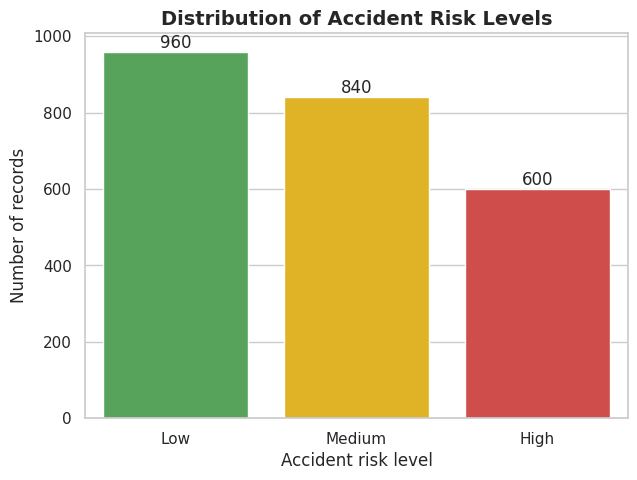

In [15]:
plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df, x="accident_risk_level", order=risk_order, palette=risk_colors)
ax.set_title("Distribution of Accident Risk Levels", fontsize=14, fontweight="bold")
ax.set_xlabel("Accident risk level")
ax.set_ylabel("Number of records")
for bar in ax.patches:                       # write the count on top of every bar
    ax.annotate(int(bar.get_height()), (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha="center", va="bottom")
plt.show()

### 8.2 Accident risk by Kumasi area

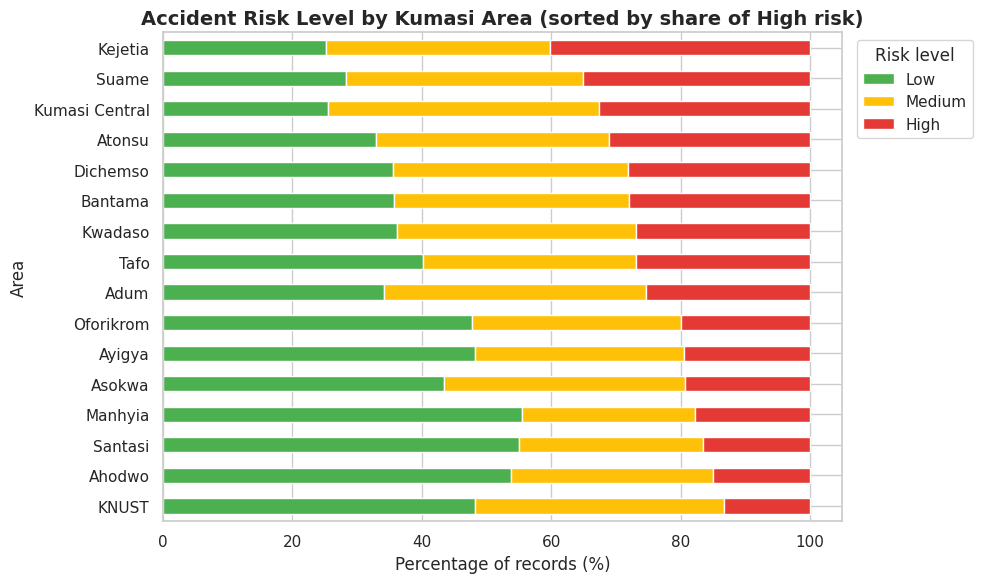

In [16]:
plot_risk_by("area", "Accident Risk Level by Kumasi Area (sorted by share of High risk)", horizontal=True)

### 8.3 Risk by weather condition

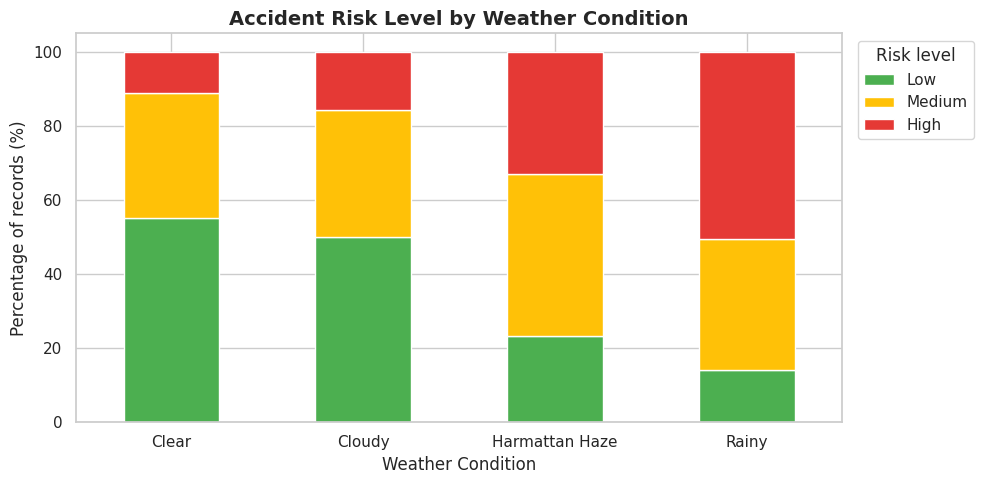

In [17]:
plot_risk_by("weather_condition", "Accident Risk Level by Weather Condition",
             order=["Clear", "Cloudy", "Harmattan Haze", "Rainy"])

### 8.4 Risk by road condition

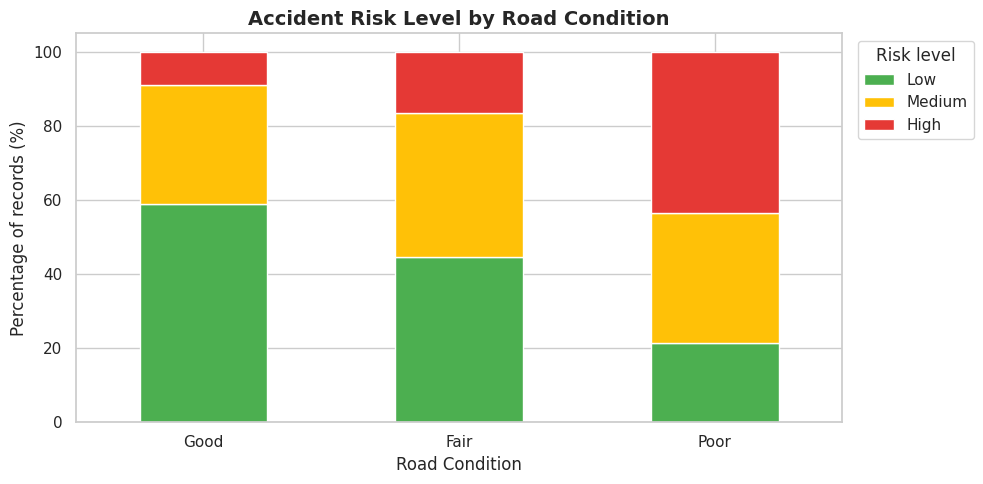

In [18]:
plot_risk_by("road_condition", "Accident Risk Level by Road Condition", order=["Good", "Fair", "Poor"])

### 8.5 Risk by lighting condition

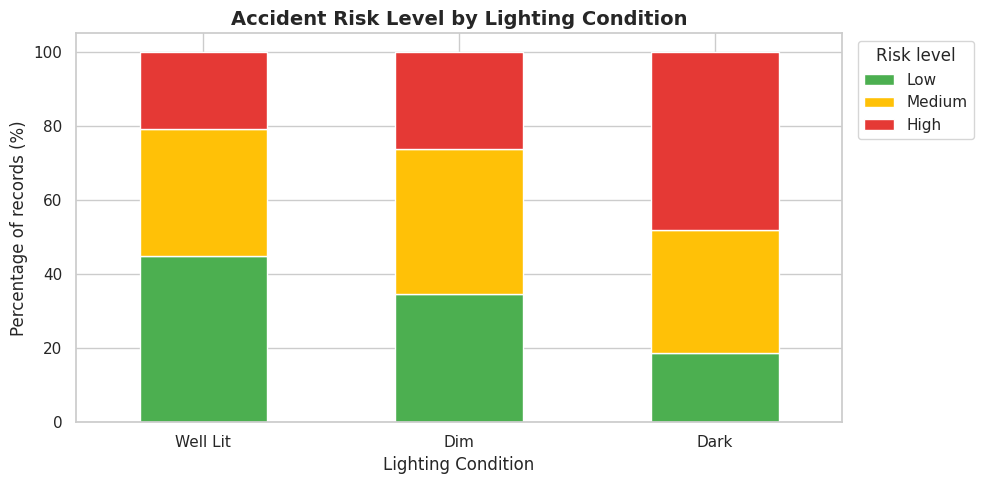

In [19]:
plot_risk_by("lighting_condition", "Accident Risk Level by Lighting Condition", order=["Well Lit", "Dim", "Dark"])

### 8.6 Risk by time of day

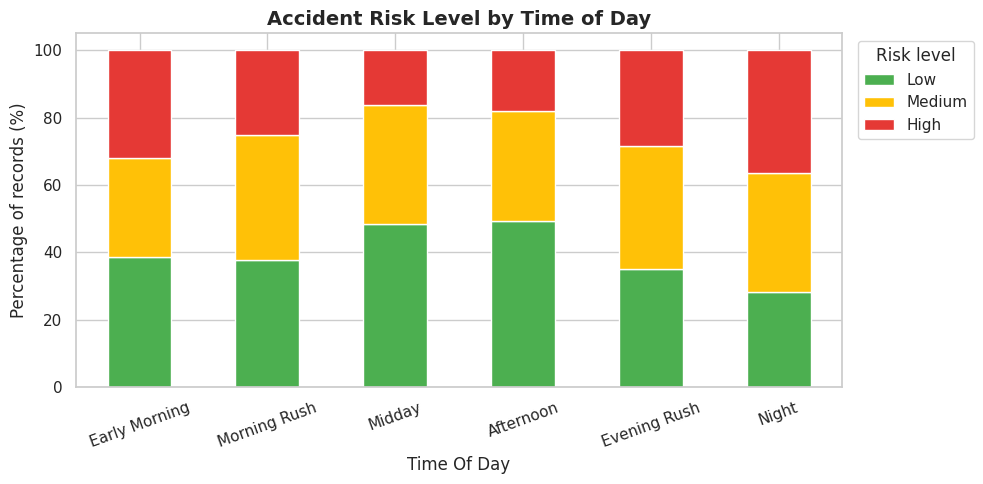

In [20]:
plot_risk_by("time_of_day", "Accident Risk Level by Time of Day", order=times, rotate=20)

### 8.7 Traffic volume versus accident risk

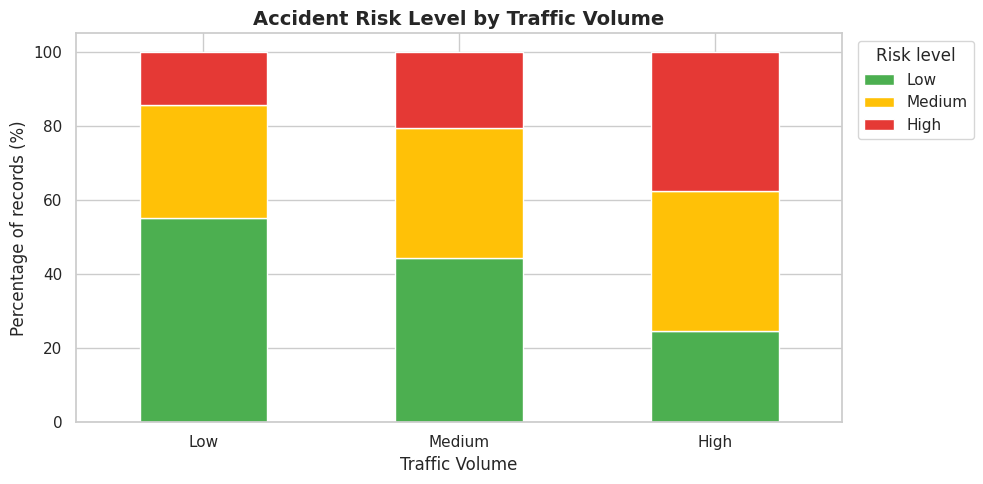

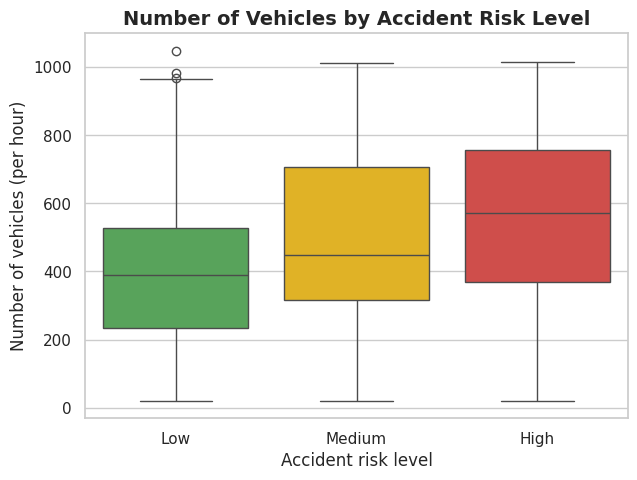

In [21]:
plot_risk_by("traffic_volume", "Accident Risk Level by Traffic Volume", order=levels)

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="accident_risk_level", y="number_of_vehicles", order=risk_order, palette=risk_colors)
plt.title("Number of Vehicles by Accident Risk Level", fontsize=14, fontweight="bold")
plt.xlabel("Accident risk level")
plt.ylabel("Number of vehicles (per hour)")
plt.show()

### 8.8 Vehicle speed versus accident risk

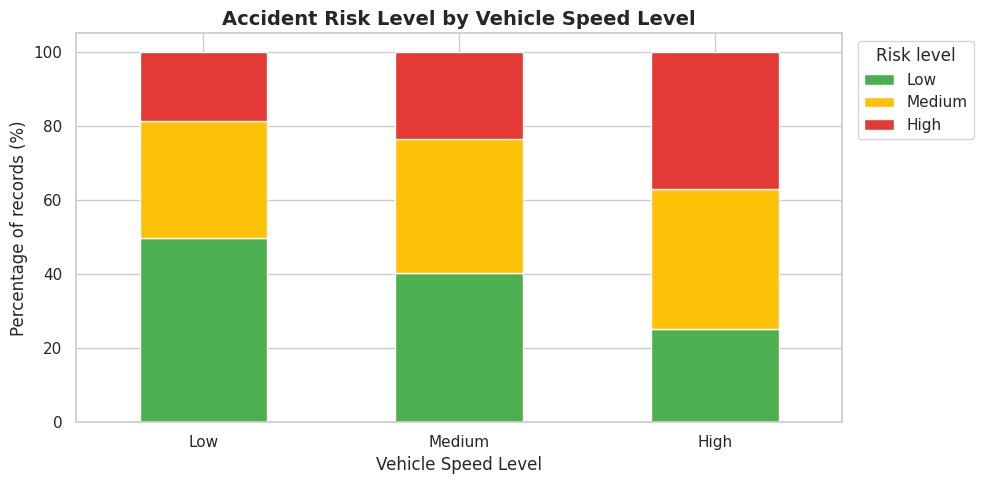

In [22]:
plot_risk_by("vehicle_speed_level", "Accident Risk Level by Vehicle Speed Level", order=levels)

### 8.9 Pedestrian activity versus accident risk

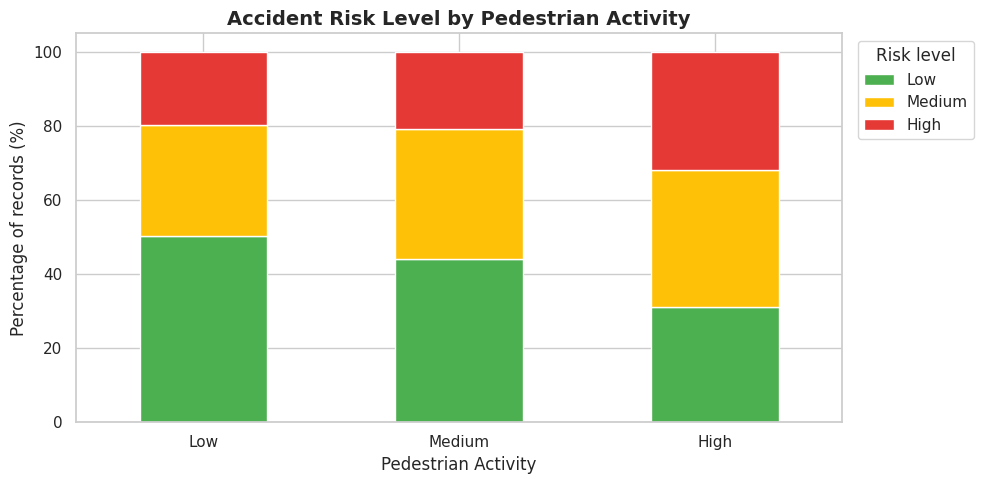

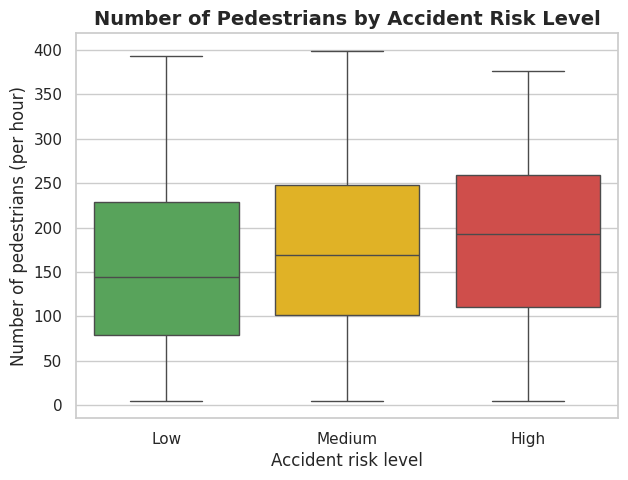

In [23]:
plot_risk_by("pedestrian_activity", "Accident Risk Level by Pedestrian Activity", order=levels)

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="accident_risk_level", y="number_of_pedestrians", order=risk_order, palette=risk_colors)
plt.title("Number of Pedestrians by Accident Risk Level", fontsize=14, fontweight="bold")
plt.xlabel("Accident risk level")
plt.ylabel("Number of pedestrians (per hour)")
plt.show()

### 8.10 Correlation heatmap for numerical variables

A correlation heatmap needs numbers. Only two columns are truly numerical, so I make a **temporary copy** of the data where ordered categories (e.g. Low < Medium < High, Good < Fair < Poor) are converted to 0, 1, 2. This copy is used **only for this graph**; the real modelling uses `OneHotEncoder` later.

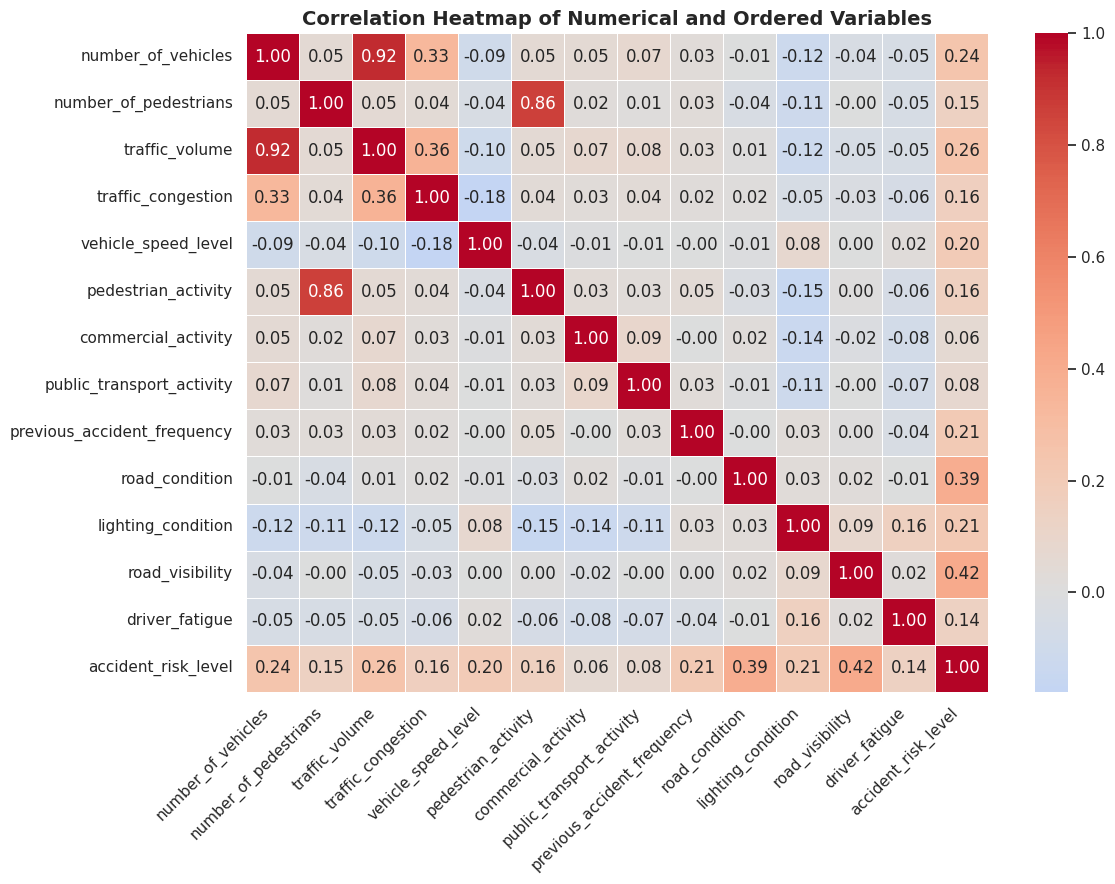

In [24]:
heat_df = df[["number_of_vehicles", "number_of_pedestrians"]].copy()

level_map = {"Low": 0, "Medium": 1, "High": 2}
for column in ["traffic_volume", "traffic_congestion", "vehicle_speed_level", "pedestrian_activity",
               "commercial_activity", "public_transport_activity", "previous_accident_frequency"]:
    heat_df[column] = df[column].map(level_map)

heat_df["road_condition"] = df["road_condition"].map({"Good": 0, "Fair": 1, "Poor": 2})
heat_df["lighting_condition"] = df["lighting_condition"].map({"Well Lit": 0, "Dim": 1, "Dark": 2})
heat_df["road_visibility"] = df["road_visibility"].map({"Good": 0, "Moderate": 1, "Poor": 2})
heat_df["driver_fatigue"] = df["driver_fatigue"].map({"No": 0, "Yes": 1})
heat_df["accident_risk_level"] = df["accident_risk_level"].map(level_map)

plt.figure(figsize=(12, 9))
sns.heatmap(heat_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation Heatmap of Numerical and Ordered Variables", fontsize=14, fontweight="bold")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [25]:
# How strongly is each variable correlated with the risk level? (sorted)
print(heat_df.corr()["accident_risk_level"].drop("accident_risk_level").sort_values(ascending=False).round(2))

road_visibility                0.42
road_condition                 0.39
traffic_volume                 0.26
number_of_vehicles             0.24
lighting_condition             0.21
previous_accident_frequency    0.21
vehicle_speed_level            0.20
traffic_congestion             0.16
pedestrian_activity            0.16
number_of_pedestrians          0.15
driver_fatigue                 0.14
public_transport_activity      0.08
commercial_activity            0.06
Name: accident_risk_level, dtype: float64


### 8.11 Important observations from the EDA

> These patterns appear because I built the simulation with these assumptions. They show that the data behaves sensibly; they are **not** findings about real Kumasi accidents.

- **Risk distribution:** Low is 40% (960 records), Medium 35% (840) and High 25% (600). The classes are reasonably balanced, with High risk being the least common, which is realistic.
- **Area:** Kejetia (about 40% High), Suame (about 35%) and Kumasi Central (about 33%) have the largest share of High-risk records. KNUST (about 13%), Ahodwo (about 15%) and Santasi (about 17%) have the lowest. This follows the busy-market/heavy-traffic profiles I assumed for the first group and the better roads and lighting I assumed for the second.
- **Weather:** Rainy conditions have by far the highest share of High risk (about 51%), compared with about 11% in clear weather. Harmattan haze is in between (about 33%).
- **Road condition:** Poor roads have about 44% High risk versus about 9% on good roads.
- **Lighting:** Dark conditions have about 48% High risk, compared with about 21% when the road is well lit.
- **Time of day:** Night (about 36%) and Early Morning (about 32%) have the highest High-risk share; Midday (about 16%) and Afternoon (about 18%) have the lowest.
- **Traffic volume:** High traffic has about 38% High risk versus about 14% for low traffic. The box plot also shows that High-risk records have a higher median number of vehicles (about 571) than Low-risk records (about 389).
- **Vehicle speed:** High speed has about 37% High risk compared with about 19% for low speed.
- **Pedestrian activity:** The effect is smaller than for road or weather conditions: about 32% High risk for high pedestrian activity versus about 20% for low.
- **Correlation heatmap:** The variables most strongly correlated with the risk level are `road_visibility` (about 0.42) and `road_condition` (about 0.39), followed by `traffic_volume` (about 0.26) and `number_of_vehicles` (about 0.24). `number_of_vehicles` is strongly related to `traffic_volume` (about 0.92) and `number_of_pedestrians` to `pedestrian_activity` (about 0.86), because the counts were generated from those levels. They carry overlapping information.
- **Main message:** no single factor decides the risk. Risk is high when several unfavourable conditions occur together, which is why a machine-learning model that combines all of them is useful.

## 9. Data Preprocessing

Machine-learning algorithms work with numbers, not text such as "Rainy" or "Suame". Numerical columns also have very different scales (vehicles in the hundreds, pedestrians in the tens). Preprocessing fixes these problems.

### 9.1 Separate the input features (X) from the target (y)

In [26]:
# X = the inputs the model will use; y = the answer we want the model to predict
X = df.drop("accident_risk_level", axis=1)
y = df["accident_risk_level"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (2400, 18)
y shape: (2400,)


### 9.2 Identify categorical and numerical features

In [27]:
categorical_features = X.select_dtypes(include=["object", "string"]).columns.tolist()
numerical_features = X.select_dtypes(include="number").columns.tolist()

print("Categorical features (", len(categorical_features), "):", categorical_features)
print()
print("Numerical features (", len(numerical_features), "):", numerical_features)

Categorical features ( 16 ): ['area', 'day_of_week', 'time_of_day', 'weather_condition', 'road_condition', 'lighting_condition', 'traffic_volume', 'traffic_congestion', 'road_type', 'vehicle_speed_level', 'pedestrian_activity', 'commercial_activity', 'public_transport_activity', 'driver_fatigue', 'road_visibility', 'previous_accident_frequency']

Numerical features ( 2 ): ['number_of_vehicles', 'number_of_pedestrians']


### 9.3 Build the preprocessor with `ColumnTransformer`

| Feature type | Method | Why it is necessary |
|---|---|---|
| Categorical | `OneHotEncoder` | Turns each category into its own 0/1 column (e.g. `weather_condition_Rainy`). This avoids giving text categories a fake order such as Kejetia = 1, Suame = 2. `handle_unknown="ignore"` prevents an error if a new category appears later. |
| Numerical | `StandardScaler` | Rescales numbers to a mean of 0 and a standard deviation of 1, so large numbers (vehicles) do not dominate small ones (pedestrians). This matters especially for Logistic Regression. |

`ColumnTransformer` applies the right method to the right columns. Later I place it inside a `Pipeline` together with the model. The pipeline learns the encoding and scaling **only from the training data** and then applies the same rules to the test data. This prevents **data leakage** (information from the test set accidentally influencing training).

In [28]:
preprocessor = ColumnTransformer(transformers=[
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ("numerical", StandardScaler(), numerical_features),
])
print(preprocessor)

ColumnTransformer(transformers=[('categorical',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['area', 'day_of_week', 'time_of_day',
                                  'weather_condition', 'road_condition',
                                  'lighting_condition', 'traffic_volume',
                                  'traffic_congestion', 'road_type',
                                  'vehicle_speed_level', 'pedestrian_activity',
                                  'commercial_activity',
                                  'public_transport_activity', 'driver_fatigue',
                                  'road_visibility',
                                  'previous_accident_frequency']),
                                ('numerical', StandardScaler(),
                                 ['number_of_vehicles',
                                  'number_of_pedestrians'])])


## 10. Train-Test Split

I split the data into **80% training** and **20% testing** with `random_state=42`, so anyone running the notebook gets the same split. I also use `stratify=y` so that Low, Medium and High keep about the same proportions in both parts.

**Why the test set must stay unseen:** the test set acts like *new, real-world situations* the model has never met. If the model (or the preprocessing) saw the test data during training, the test score would look better than the model really is, just like a student who has seen the exam questions in advance. Only the training set is used to learn; the test set is used **once** at the end to judge the model.

In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)

print("Training set:", X_train.shape)
print("Testing set: ", X_test.shape)
print()
print("Training class proportions (%):")
print((y_train.value_counts(normalize=True) * 100).round(1))
print()
print("Testing class proportions (%):")
print((y_test.value_counts(normalize=True) * 100).round(1))

Training set: (1920, 18)
Testing set:  (480, 18)

Training class proportions (%):
accident_risk_level
Low       40.0
Medium    35.0
High      25.0
Name: proportion, dtype: float64

Testing class proportions (%):
accident_risk_level
Low       40.0
Medium    35.0
High      25.0
Name: proportion, dtype: float64


## 11. Model Training

For each model I do four things: **create** the pipeline, **train** it with `.fit()` on the training data, **predict** with `.predict()` on the test data, and then **evaluate** it (full evaluation in Section 12).

### 11.1 Logistic Regression
**In simple language:** Logistic Regression gives each input a *weight*. Risky conditions push the score up, safe conditions push it down, and the final score is converted into probabilities for Low, Medium and High. It is simple, fast and easy to explain.

In [30]:
# 1. Create
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42)),
])
# 2. Train (the preprocessor learns from the training data only)
logistic_model.fit(X_train, y_train)
# 3. Predict
logistic_predictions = logistic_model.predict(X_test)
# 4. Quick check
print("Logistic Regression test accuracy:", round(accuracy_score(y_test, logistic_predictions), 4))

Logistic Regression test accuracy: 0.8


### 11.2 Decision Tree Classifier
**In simple language:** A Decision Tree asks a series of yes/no questions, for example *"Is the road condition Poor?" → "Is the speed High?"*, and follows the branches until it reaches a risk level. It is easy to visualise, but a tree that grows too deep memorises the training data (**overfitting**), so I limit it with `max_depth=6` and `min_samples_leaf=10`.

In [31]:
tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(max_depth=6, min_samples_leaf=10, random_state=42)),
])
tree_model.fit(X_train, y_train)
tree_predictions = tree_model.predict(X_test)
print("Decision Tree test accuracy:", round(accuracy_score(y_test, tree_predictions), 4))

Decision Tree test accuracy: 0.6021


### 11.3 Random Forest Classifier
**In simple language:** A Random Forest builds many different decision trees (here 300), each trained on a slightly different random sample of the data. Every tree votes, and the majority vote becomes the prediction. Combining many trees is usually more stable and less likely to overfit than a single tree.

In [32]:
forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=42, n_jobs=-1)),
])
forest_model.fit(X_train, y_train)
forest_predictions = forest_model.predict(X_test)
print("Random Forest test accuracy:", round(accuracy_score(y_test, forest_predictions), 4))

Random Forest test accuracy: 0.7063


## 12. Model Evaluation

Accuracy alone is not enough, so I use four metrics. For three classes I use the **weighted average**, which calculates the metric for each class and averages them according to how many records each class has.

| Metric | Simple meaning |
|---|---|
| **Accuracy** | How many predictions were correct overall. |
| **Precision** | When the model says a case belongs to a risk class, how often is it right? (How reliable its predictions are.) |
| **Recall** | Out of all the cases that really belong to a risk class, how many did the model find? |
| **F1-score** | A balance between precision and recall. It is low if either one is low. |

Example: if the model labels 10 situations as *High* and 8 really are High, precision for High is 80%. If there are 20 truly High situations and the model finds 8 of them, recall for High is 40%.

In [33]:
# Store the predictions of the three models in one place
all_predictions = {
    "Logistic Regression": logistic_predictions,
    "Decision Tree": tree_predictions,
    "Random Forest": forest_predictions,
}

# Calculate the four metrics for each model
results = []
for model_name, predictions in all_predictions.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, average="weighted"),
        "Recall": recall_score(y_test, predictions, average="weighted"),
        "F1-score": f1_score(y_test, predictions, average="weighted"),
    })
results_df = pd.DataFrame(results).set_index("Model")
results_df.round(4)

,Accuracy,Precision,Recall,F1-score
Model,,,,
Logistic Regression,0.8000,0.8052,0.8000,0.8017
Decision Tree,0.6021,0.6105,0.6021,0.6046
Random Forest,0.7062,0.7148,0.7062,0.7067


### 12.1 Classification reports (per-class results)

In [34]:
for model_name, predictions in all_predictions.items():
    print("=" * 60)
    print(model_name)
    print("=" * 60)
    print(classification_report(y_test, predictions, labels=risk_order))

Logistic Regression
              precision    recall  f1-score   support

         Low       0.84      0.83      0.84       192
      Medium       0.70      0.76      0.73       168
        High       0.90      0.81      0.85       120

    accuracy                           0.80       480
   macro avg       0.81      0.80      0.80       480
weighted avg       0.81      0.80      0.80       480

Decision Tree
              precision    recall  f1-score   support

         Low       0.69      0.69      0.69       192
      Medium       0.47      0.52      0.50       168
        High       0.68      0.57      0.62       120

    accuracy                           0.60       480
   macro avg       0.61      0.60      0.60       480
weighted avg       0.61      0.60      0.60       480

Random Forest
              precision    recall  f1-score   support

         Low       0.77      0.82      0.80       192
      Medium       0.58      0.63      0.60       168
        High       0.82    

The classification report shows precision, recall and F1-score **for each class** (Low, Medium, High), and `support` is the number of test records in that class. The `macro avg` treats all classes equally, while the `weighted avg` accounts for class size.

## 13. Model Comparison

I compare the models in a table and a chart. To make the choice more reliable than a single test result, I also run **5-fold cross-validation** on the *training data only*: the training data is split into 5 parts, the model is trained on 4 and tested on 1, five times, and the scores are averaged. The test set remains untouched by this step.

In [35]:
models = {"Logistic Regression": logistic_model, "Decision Tree": tree_model, "Random Forest": forest_model}

cv_scores = {}
for model_name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring="accuracy")
    cv_scores[model_name] = scores.mean()

comparison_df = results_df.copy()
comparison_df["CV Accuracy (train, 5-fold)"] = pd.Series(cv_scores)
comparison_df = comparison_df.round(4)
comparison_df

,Accuracy,Precision,Recall,F1-score,"CV Accuracy (train, 5-fold)"
Model,,,,,
Logistic Regression,0.8000,0.8052,0.8000,0.8017,0.7292
Decision Tree,0.6021,0.6105,0.6021,0.6046,0.5932
Random Forest,0.7062,0.7148,0.7062,0.7067,0.6682


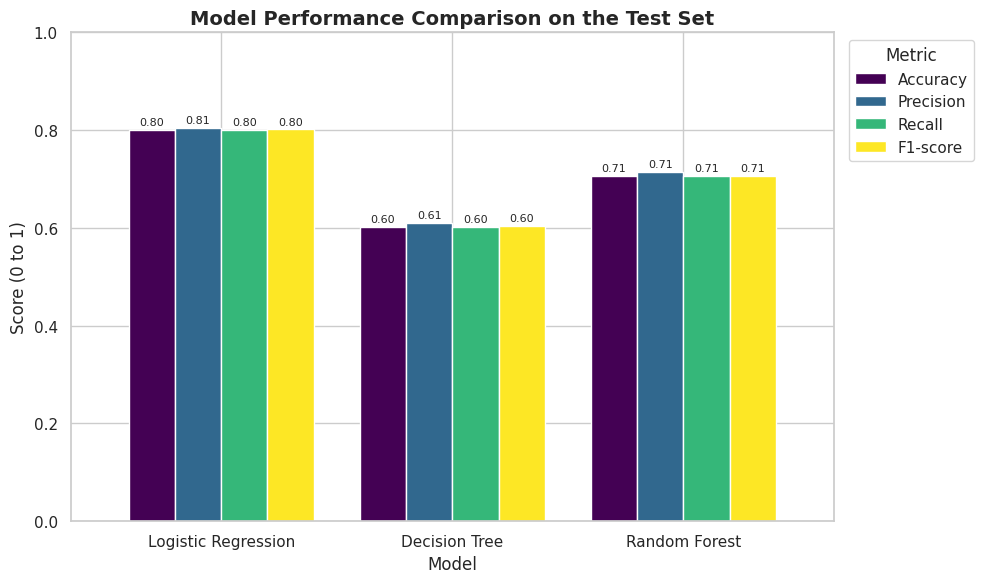

In [36]:
# Bar chart comparing the four test metrics
ax = comparison_df[["Accuracy", "Precision", "Recall", "F1-score"]].plot(
    kind="bar", figsize=(10, 6), width=0.8, colormap="viridis")
ax.set_title("Model Performance Comparison on the Test Set", fontsize=14, fontweight="bold")
ax.set_xlabel("Model")
ax.set_ylabel("Score (0 to 1)")
ax.set_ylim(0, 1.0)
plt.xticks(rotation=0)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=8, padding=2)
ax.legend(title="Metric", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

### 13.1 Select the best model

The best model is **not chosen arbitrarily**. I select the model with the highest **weighted F1-score** on the test set, because F1 balances precision and recall across all three classes. I then check that the cross-validation result supports this choice.

In [37]:
best_model_name = comparison_df["F1-score"].idxmax()
best_model = models[best_model_name]
best_predictions = all_predictions[best_model_name]

print("Best model based on test F1-score:", best_model_name)
print("Test F1-score:", comparison_df.loc[best_model_name, "F1-score"])
print("Best model by cross-validation accuracy:", comparison_df["CV Accuracy (train, 5-fold)"].idxmax())

Best model based on test F1-score: Logistic Regression
Test F1-score: 0.8017
Best model by cross-validation accuracy: Logistic Regression


**Results in this run** (exact decimals may differ slightly on other library versions):

| Model | Accuracy | F1-score | CV accuracy (training) |
|---|---|---|---|
| Logistic Regression | about 0.80 | about 0.80 | about 0.73 |
| Random Forest | about 0.71 | about 0.71 | about 0.67 |
| Decision Tree | about 0.60 | about 0.60 | about 0.59 |

**Decision:** Logistic Regression is the best-performing model. It has the highest test F1-score and also the highest cross-validation accuracy, so the choice is supported by two independent measurements.

**Why did the simpler model win?** The synthetic risk score was built by *adding up* risk points for each condition. Logistic Regression is a model that also works by adding up weighted evidence, so it matches the structure of this data very well. The single Decision Tree is the weakest because one tree reacts strongly to noise. The Random Forest improves on a single tree but still does not beat Logistic Regression here. **On real accident data the ranking could be different**, so this result should not be generalised.

## 14. Confusion Matrix

A confusion matrix shows exactly **where the model is right and where it is confused**.
- **Rows** = the **actual** (true) risk level.
- **Columns** = the risk level **predicted** by the model.
- The **diagonal** (top-left to bottom-right) contains **correct** predictions.
- Numbers **off the diagonal** are **mistakes**; for example, the cell in row *High*, column *Medium* counts situations that were really High risk but were predicted as Medium.

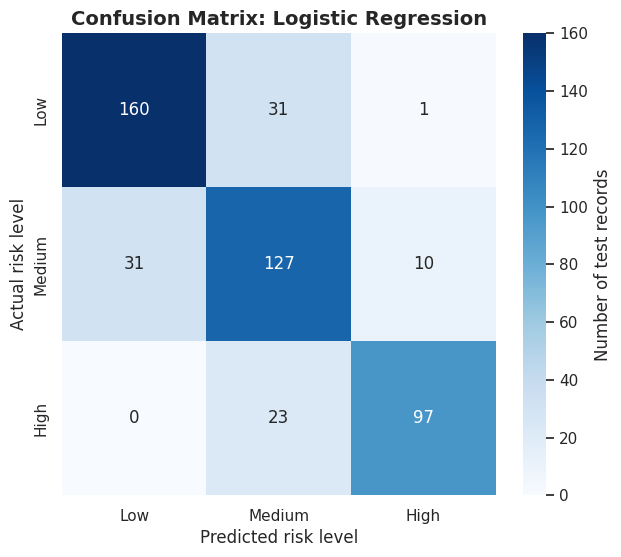

In [38]:
cm = confusion_matrix(y_test, best_predictions, labels=risk_order)

plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=risk_order, yticklabels=risk_order,
            cbar_kws={"label": "Number of test records"})
plt.title(f"Confusion Matrix: {best_model_name}", fontsize=14, fontweight="bold")
plt.xlabel("Predicted risk level")
plt.ylabel("Actual risk level")
plt.show()

In [39]:
# Turn the matrix into plain sentences using the real numbers from the run
cm_df = pd.DataFrame(cm, index=risk_order, columns=risk_order)
for actual in risk_order:
    correct = cm_df.loc[actual, actual]
    total = cm_df.loc[actual].sum()
    print(f"Actual {actual:<6}: {correct} of {total} predicted correctly ({correct / total:.0%}).")

print()
for actual in risk_order:
    for predicted in risk_order:
        if actual != predicted and cm_df.loc[actual, predicted] > 0:
            print(f"  {cm_df.loc[actual, predicted]:>3} situations were really {actual} but predicted as {predicted}.")

Actual Low   : 160 of 192 predicted correctly (83%).
Actual Medium: 127 of 168 predicted correctly (76%).
Actual High  : 97 of 120 predicted correctly (81%).

   31 situations were really Low but predicted as Medium.
    1 situations were really Low but predicted as High.
   31 situations were really Medium but predicted as Low.
   10 situations were really Medium but predicted as High.
   23 situations were really High but predicted as Medium.


**How to read this matrix (using the numbers printed above):**
- **Correct classifications:** the model correctly identified most Low, Medium and High cases (the diagonal). Low and High are recognised best; Medium is the hardest class.
- **Typical mistakes:** nearly all errors are between **neighbouring** classes, mainly Low ↔ Medium and High → Medium. For example, a High-risk situation predicted as Medium is a mistake, but it is "close". Very few Low cases are labelled High, and no High case is labelled Low.
- **Why Medium is hardest:** it sits between the other two classes, and the random noise added during data creation makes borderline situations genuinely ambiguous.
- **Why this matters:** the most serious error type would be calling a really High-risk situation Low. The model avoids this error in this test set, although High cases predicted as Medium still show room for improvement.

## 15. New Prediction

Now I test the best model on a **new hypothetical Kumasi situation** that is not in the dataset. The prediction comes **from the trained model**. It is not typed in manually. The new case must have the same columns as the training data, and the pipeline automatically applies the same encoding and scaling.

*Time note:* 8:00 PM falls in the **Night** period (20:00-4:59) used in this project.

In [40]:
new_situation = pd.DataFrame([{
    "area": "Suame",
    "day_of_week": "Friday",
    "time_of_day": "Night",                      # 8:00 PM
    "weather_condition": "Rainy",
    "road_condition": "Poor",
    "lighting_condition": "Dark",
    "traffic_volume": "High",
    "traffic_congestion": "High",
    "road_type": "Major Road",
    "vehicle_speed_level": "High",
    "pedestrian_activity": "High",
    "commercial_activity": "High",
    "public_transport_activity": "High",
    "driver_fatigue": "Yes",
    "road_visibility": "Poor",
    "number_of_vehicles": 850,
    "number_of_pedestrians": 300,
    "previous_accident_frequency": "High",
}])
new_situation.T.rename(columns={0: "Value"})       # show the case in a readable vertical layout

,Value
area,Suame
day_of_week,Friday
time_of_day,Night
weather_condition,Rainy
road_condition,Poor
lighting_condition,Dark
traffic_volume,High
traffic_congestion,High
road_type,Major Road
vehicle_speed_level,High


In [41]:
predicted_risk = best_model.predict(new_situation)[0]
probabilities = best_model.predict_proba(new_situation)[0]

print(f"Model used: {best_model_name}")
print(f"Predicted Accident Risk: {predicted_risk.upper()}")
print()
print("Model's confidence for each class:")
for class_name, probability in zip(best_model.classes_, probabilities):
    print(f"  {class_name:<7}: {probability:.1%}")

Model used: Logistic Regression
Predicted Accident Risk: HIGH

Model's confidence for each class:
  High   : 100.0%
  Low    : 0.0%
  Medium : 0.0%


To check that the model really responds to the inputs, I also test a deliberately **safe** situation and a **mixed** situation.

In [42]:
safe_situation = pd.DataFrame([{
    "area": "Ahodwo", "day_of_week": "Sunday", "time_of_day": "Midday",
    "weather_condition": "Clear", "road_condition": "Good", "lighting_condition": "Well Lit",
    "traffic_volume": "Low", "traffic_congestion": "Low", "road_type": "Minor Road",
    "vehicle_speed_level": "Low", "pedestrian_activity": "Low", "commercial_activity": "Low",
    "public_transport_activity": "Low", "driver_fatigue": "No", "road_visibility": "Good",
    "number_of_vehicles": 120, "number_of_pedestrians": 30, "previous_accident_frequency": "Low",
}])

mixed_situation = pd.DataFrame([{
    "area": "Asokwa", "day_of_week": "Wednesday", "time_of_day": "Evening Rush",
    "weather_condition": "Rainy", "road_condition": "Fair", "lighting_condition": "Dim",
    "traffic_volume": "High", "traffic_congestion": "Medium", "road_type": "Junction",
    "vehicle_speed_level": "Medium", "pedestrian_activity": "Medium", "commercial_activity": "Medium",
    "public_transport_activity": "Medium", "driver_fatigue": "No", "road_visibility": "Moderate",
    "number_of_vehicles": 600, "number_of_pedestrians": 140, "previous_accident_frequency": "Medium",
}])

for label, case in [("Safe situation (Ahodwo, Sunday midday)", safe_situation),
                    ("Mixed situation (Asokwa, Wednesday evening rush, rainy)", mixed_situation)]:
    result = best_model.predict(case)[0]
    chance = best_model.predict_proba(case)[0]
    summary = ", ".join(f"{c}: {p:.0%}" for c, p in zip(best_model.classes_, chance))
    print(label)
    print(f"   Predicted Accident Risk: {result.upper()}   ({summary})")

Safe situation (Ahodwo, Sunday midday)


   Predicted Accident Risk: LOW   (High: 0%, Low: 100%, Medium: 0%)
Mixed situation (Asokwa, Wednesday evening rush, rainy)
   Predicted Accident Risk: MEDIUM   (High: 16%, Low: 5%, Medium: 79%)


## 16. Model Interpretation

Understanding *why* a model makes its predictions is important. Because **Logistic Regression** was selected, I look at its **coefficients**: a positive coefficient pushes a situation towards High risk and a negative one pushes it away. To compare, I also show the **feature importance** from the Random Forest, which measures how much each variable helped the forest's trees to make decisions.

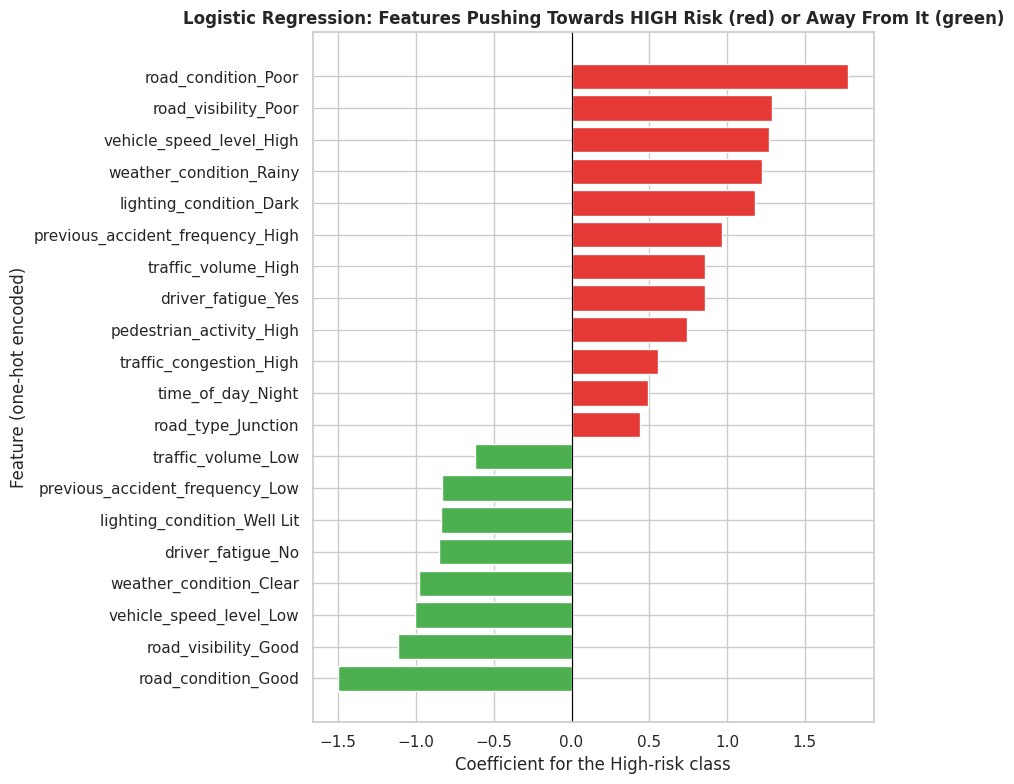

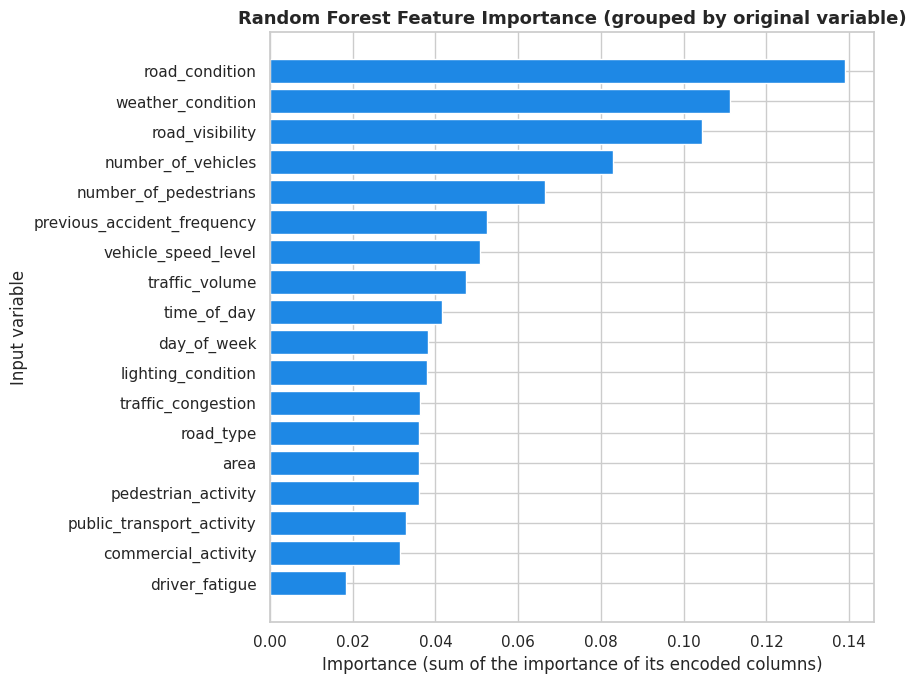

Top 8 variables by Random Forest importance:
road_condition                 0.139
weather_condition              0.111
road_visibility                0.105
number_of_vehicles             0.083
number_of_pedestrians          0.067
previous_accident_frequency    0.052
vehicle_speed_level            0.051
traffic_volume                 0.047
dtype: float64


In [43]:
# ---------- Part A: Logistic Regression coefficients for the HIGH class (the selected model) ----------
# Get the names of all columns created by OneHotEncoder + StandardScaler
feature_names = logistic_model.named_steps["preprocessor"].get_feature_names_out()
feature_names = [name.split("__", 1)[1] for name in feature_names]      # remove the "categorical__" prefix

high_row = list(logistic_model.classes_).index("High")                  # which row of coef_ belongs to High
coefficients = pd.Series(logistic_model.named_steps["classifier"].coef_[high_row], index=feature_names)
coefficients = coefficients.sort_values()

# Show the 8 strongest "lower risk" and the 12 strongest "higher risk" features
top_coefficients = pd.concat([coefficients.head(8), coefficients.tail(12)])
bar_colors = ["#4CAF50" if value < 0 else "#E53935" for value in top_coefficients]

plt.figure(figsize=(9, 8))
plt.barh(top_coefficients.index, top_coefficients.values, color=bar_colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Logistic Regression: Features Pushing Towards HIGH Risk (red) or Away From It (green)",
          fontsize=12, fontweight="bold")
plt.xlabel("Coefficient for the High-risk class")
plt.ylabel("Feature (one-hot encoded)")
plt.tight_layout()
plt.show()

# ---------- Part B: Random Forest feature importance (added for comparison) ----------
forest_importance = pd.Series(forest_model.named_steps["classifier"].feature_importances_, index=feature_names)

# One-hot encoding split each variable into many columns, so I add them back together per original variable
importance_by_variable = {}
for variable in categorical_features:
    importance_by_variable[variable] = forest_importance[[n for n in feature_names if n.startswith(variable + "_")]].sum()
for variable in numerical_features:
    importance_by_variable[variable] = forest_importance[variable]
importance_by_variable = pd.Series(importance_by_variable).sort_values(ascending=True)

plt.figure(figsize=(9, 7))
plt.barh(importance_by_variable.index, importance_by_variable.values, color="#1E88E5")
plt.title("Random Forest Feature Importance (grouped by original variable)", fontsize=13, fontweight="bold")
plt.xlabel("Importance (sum of the importance of its encoded columns)")
plt.ylabel("Input variable")
plt.tight_layout()
plt.show()

print("Top 8 variables by Random Forest importance:")
print(importance_by_variable.sort_values(ascending=False).head(8).round(3))

**What the model appears to consider important**
- **Logistic Regression coefficients:** the features pushing a situation most strongly towards **High** risk are *poor road condition*, *poor visibility*, *high vehicle speed*, *rainy weather* and *dark lighting*, followed by high previous accident frequency, high traffic volume, driver fatigue and high pedestrian activity. *Good road condition*, *good visibility*, *low speed* and *clear weather* push the prediction **away** from High risk.
- **Random Forest feature importance:** the top variables are `road_condition`, `weather_condition` and `road_visibility`, followed by the vehicle and pedestrian counts, previous accident frequency, vehicle speed and traffic volume. The two models broadly agree on the main drivers.
- **Area and day of week** have little direct importance. In the simulation, area influences risk mainly **through** traffic, pedestrians and road quality, so once those are known the area name adds little.

**Important warning:** feature importance and coefficients show which variables contributed strongly to the *model's decisions*. They do **not** prove that a variable *causes* accidents. In this project the importance simply reflects the rules I used to build the synthetic data. With real data, hidden factors (confounders) could also be involved.

## 17. Limitations

1. **Synthetic dataset:** the data was generated by rules I wrote. The model mostly rediscovers those rules, so its performance says little about real-world accuracy.
2. **No official accident records:** the data does not come from the Ghana Police Service, MTTD, NRSA or hospitals, so it cannot be used for official risk statements.
3. **No real-time traffic information:** the model does not know the traffic, weather or road status *right now*; it only uses the values typed in.
4. **Simulated vs real-world conditions:** real accidents involve many things not captured here (vehicle condition, driver behaviour, road design, drunk driving, motorbike (okada) activity, market-day crowds, road works).
5. **Model performance may change with real data:** real data is messier, with missing values, reporting bias and rare severe accidents. Scores would probably be different and models would need re-tuning.
6. **Risk, not prediction of an event:** the system estimates a *risk level* for given conditions. It cannot say that an accident will or will not happen at a particular time or place.
7. **Three risk classes are a simplification:** actual severity (injury, fatality) is more detailed than Low/Medium/High.

## 18. Future Improvements

- **Real accident records** from police, MTTD/NRSA and hospital or emergency-service records, with proper permission, to train on real outcomes.
- **GPS/location data** so that risk can be mapped to exact junctions, roundabouts and road segments instead of broad areas.
- **Real-time traffic data** (for example from traffic APIs or sensors) for current congestion and vehicle counts.
- **Weather APIs** to automatically fetch rain, visibility and Harmattan conditions.
- **Road-condition information** such as potholes, drainage problems and road works from city or road-authority surveys.
- **Traffic-camera data** to count vehicles and pedestrians automatically.
- **Emergency-service records** (ambulance and fire-service response data) to validate and improve risk levels.
- **Larger datasets** covering several years and all seasons, so the model can generalise better.
- **Real-time prediction** in a web or mobile app (for example with Streamlit or Flask) that warns road users and planners as conditions change.
- **Better modelling:** try gradient boosting, hyper-parameter tuning, and class-imbalance handling once real data is used.

## 19. Conclusion

This project built a complete machine-learning workflow for estimating **road accident risk levels (Low, Medium, High) in Kumasi**. I generated a reproducible synthetic dataset of 2,400 records covering 16 Kumasi areas, explored it with ten types of visualisations, preprocessed it with a `ColumnTransformer` and `Pipeline` (one-hot encoding and scaling, with no data leakage), and trained three classifiers on an 80/20 train-test split.

**Logistic Regression** performed best (about 80% accuracy and about 0.80 weighted F1-score), followed by Random Forest (about 71%) and the Decision Tree (about 60%). The selection was based on F1-score and confirmed by cross-validation. The best model classified a hypothetical rainy, dark Friday night in Suame with heavy traffic, high speed and a fatigued driver as **High risk**, a safe Sunday midday in Ahodwo as **Low risk**, and a moderately risky situation as **Medium risk**. Road condition, visibility, weather, vehicle speed and lighting were the most influential factors.

Because the data is **synthetic and created for academic demonstration**, these results do not describe real accident statistics. The project's value is in demonstrating the full methodology, which could be applied to real Kumasi accident, traffic and weather data in future work.